In [1]:
import os 
import tensorflow as tf 
from tensorflow.keras import layers, models

In [2]:
types = ["normal", "pneumonia", "tuberculosis"]
# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


In [3]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    'data/train',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    'data/test',
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    'data/val',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 20450 files belonging to 3 classes.
Found 2569 files belonging to 3 classes.
Found 2534 files belonging to 3 classes.


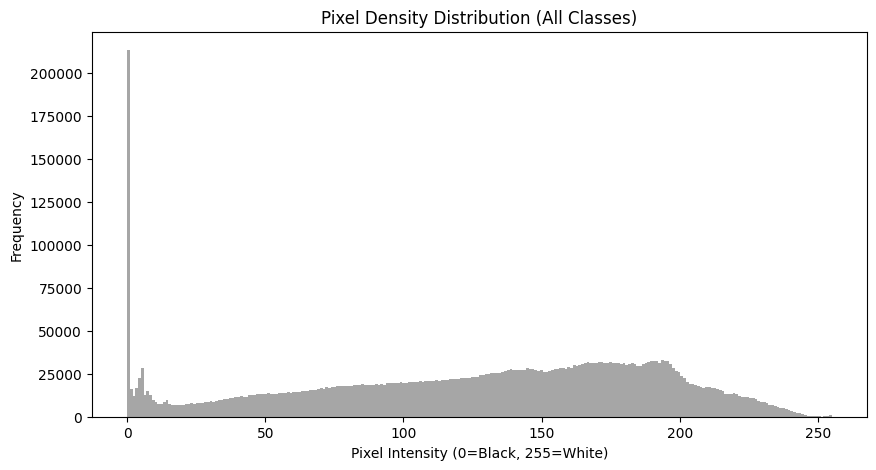

2026-02-15 04:05:57.626026: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Take one batch (e.g., 32 images)
for images, labels in train_ds.take(1):
    # Flatten all pixels in the batch into a 1D array
    pixels = images.numpy().flatten()
    
    plt.figure(figsize=(10, 5))
    plt.hist(pixels, bins=256, color='gray', alpha=0.7)
    plt.title('Pixel Density Distribution (All Classes)')
    plt.xlabel('Pixel Intensity (0=Black, 255=White)')
    plt.ylabel('Frequency')
    plt.show()

2026-02-15 04:07:22.554598: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


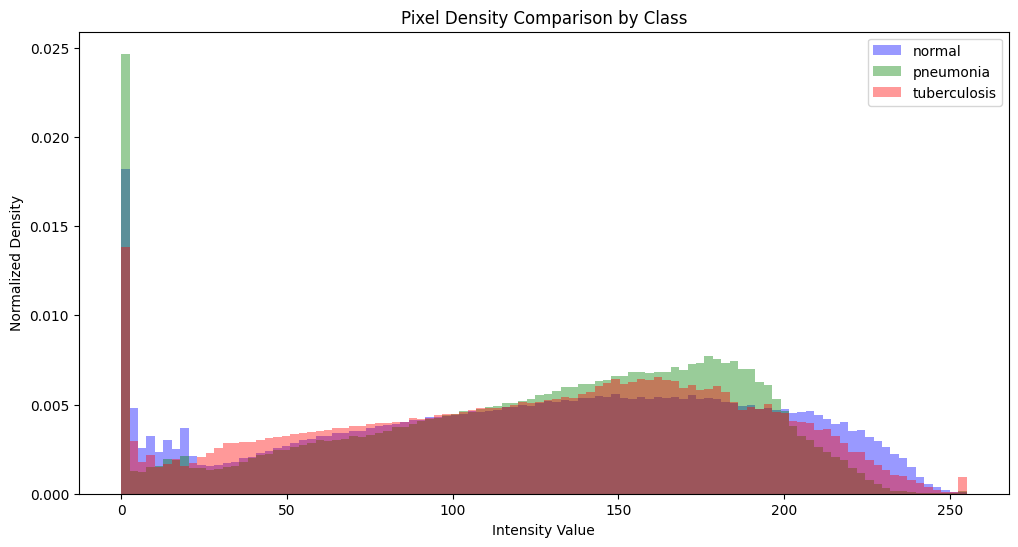

In [5]:
def plot_class_histograms(dataset, class_names):
    plt.figure(figsize=(12, 6))
    
    # Store pixels for each class
    class_pixels = {name: [] for name in class_names}
    
    # Analyze 5 batches for a good sample size
    for images, labels in dataset.take(5):
        images = images.numpy()
        labels = np.argmax(labels.numpy(), axis=1)
        
        for i in range(len(images)):
            cls_name = class_names[labels[i]]
            # Add flattened pixels of this specific image
            class_pixels[cls_name].extend(images[i].flatten())

    # Plotting
    colors = ['blue', 'green', 'red']
    for i, name in enumerate(class_names):
        plt.hist(class_pixels[name], bins=100, alpha=0.4, 
                 label=name, color=colors[i], density=True)

    plt.title('Pixel Density Comparison by Class')
    plt.xlabel('Intensity Value')
    plt.ylabel('Normalized Density')
    plt.legend()
    plt.show()

# Usage
plot_class_histograms(train_ds, train_ds.class_names)

In [ ]:
model = models.Sequential([
    # Preprocessing: Rescale inputs to [0, 1]
    layers.Rescaling(1./255, input_shape=(224, 224, 3)),
    
    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Flatten and Classify
    layers.Flatten(),
    layers.Dense(128, activation='relu'),  
    layers.Dropout(0.5), # Helps prevent overfitting by dropping out 0.5 acc 
    layers.Dense(3, activation='softmax') # Softmax for multi-class probability
])

/Users/joshan/Documents/final-year-project/backend/.venv/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [53]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20
)

Epoch 1/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 307s 478ms/step - accuracy: 0.7029 - loss: 0.6093 - val_accuracy: 0.7364 - val_loss: 0.4970
Epoch 2/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 301s 470ms/step - accuracy: 0.7392 - loss: 0.4945 - val_accuracy: 0.7372 - val_loss: 0.4997
Epoch 3/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 295s 460ms/step - accuracy: 0.7494 - loss: 0.4642 - val_accuracy: 0.7518 - val_loss: 0.4396
Epoch 4/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 274s 428ms/step - accuracy: 0.7573 - loss: 0.4472 - val_accuracy: 0.7443 - val_loss: 0.4597
Epoch 5/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 260s 406ms/step - accuracy: 0.7638 - loss: 0.4328 - val_accuracy: 0.7569 - val_loss: 0.4322
Epoch 6/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 263s 411ms/step - accuracy: 0.7669 - loss: 0.4272 - val_accuracy: 0.7455 - val_loss: 0.4407
Epoch 7/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 263s 410ms/step - accuracy: 0.7673 - loss: 0.4279 - val_accuracy: 0.7553 - val_loss: 0.4332
Epoch 8/20
640/640 ━━━━━━━━━━━━━━━━━━━━ 261s 408ms/step - accuracy: 0.7714 -

In [54]:
# Save the model
model.save('chest_xray_classifier.keras')
print("Model saved successfully!")

Model saved successfully!


In [1]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

NameError: name 'model' is not defined

In [1]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get all predictions and true labels
y_pred = []
y_true = []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(labels, axis=1))

# Generate the Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = test_ds.class_names

# Plot them in heat map
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Chest X-Ray Confusion Matrix')
plt.show()

# Print Precision, Recall, and F1-Score
print(classification_report(y_true, y_pred, target_names=class_names))

NameError: name 'test_ds' is not defined

Found 2569 files belonging to 3 classes.
Evaluating model...
81/81 ━━━━━━━━━━━━━━━━━━━━ 11s 139ms/step

Classification Report:
              precision    recall  f1-score   support

      normal       0.59      0.86      0.70       925
   pneumonia       0.89      0.72      0.80       580
tuberculosis       0.89      0.62      0.73      1064

    accuracy                           0.73      2569
   macro avg       0.79      0.73      0.74      2569
weighted avg       0.78      0.73      0.73      2569



2026-02-12 15:29:34.162778: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


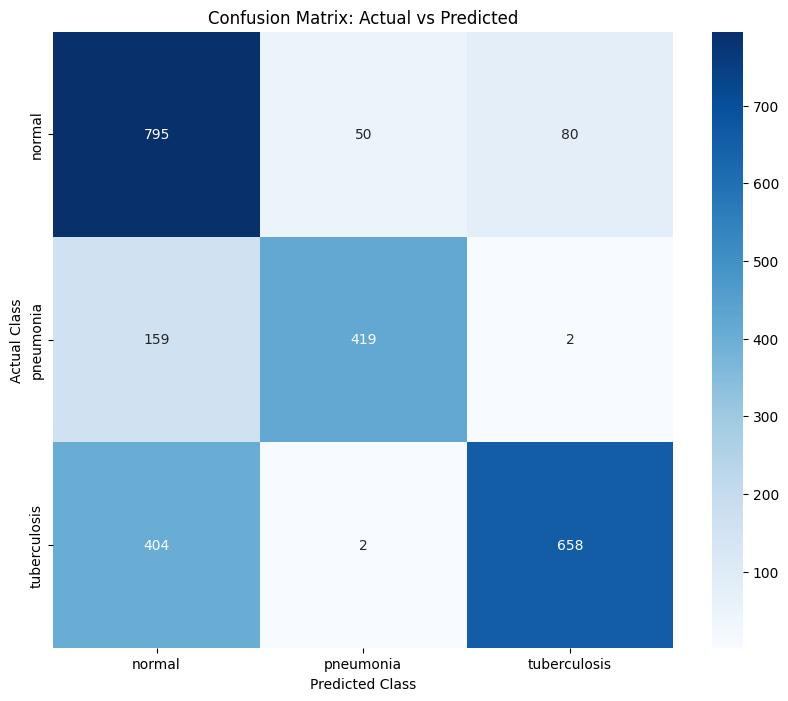

In [59]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf

# 1. Load the Test Dataset (Make sure shuffle=False for evaluation!)
test_ds = tf.keras.utils.image_dataset_from_directory(
    'data/test',
    image_size=(224, 224),
    batch_size=32,
    label_mode='categorical',
    shuffle=False  # CRITICAL: Do not shuffle for the Confusion Matrix
)

# 2. Load your saved model
model = tf.keras.models.load_model('chest_xray_classifier.keras')

# 3. Get Predictions
print("Evaluating model...")
# This method is quiet and won't trigger the "End of Sequence" warning
predictions = model.predict(test_ds)
y_pred = np.argmax(predictions, axis=1)

# 4. Get True Labels
# We extract labels from the dataset manually
y_true = np.concatenate([y for x, y in test_ds], axis=0)
y_true = np.argmax(y_true, axis=1)

# 5. Generate metrics
class_names = test_ds.class_names
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names))

# 6. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix: Actual vs Predicted')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

In [15]:
model = tf.keras.models.load_model('CX_1.keras')
# Verify the architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,508,043 (127.82 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 22,338,696 (85.22 MB)

In [17]:
import numpy as np
from tensorflow.keras.preprocessing import image

def predict_single_image(img_path, model):
    # 1. Load and resize the image
    img = image.load_img(img_path, target_size=(224, 224))
    
    # 2. Convert to array and add batch dimension
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) 
    
    # 3. Predict
    predictions = model.predict(img_array)
    
    # 4. Get class names (assuming standard order: Normal, Pneumonia, TB)
    # Note: These usually follow alphabetical order of your folders
    class_names = ['Normal', 'Pneumonia', 'Tuberculosis']
    result = class_names[np.argmax(predictions)]
    confidence = np.max(predictions) * 100
    
    return result, confidence

# Usage:
label, score = predict_single_image('data/test/normal/normal-921.jpg', model)
print(f"Prediction: {label} ({score:.2f}%)")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Prediction: Normal (56.73%)
